# Application of Structural Break and Changepoint Analysis

## A Study of India's Consumer Price Index (2013–2024)

**Project:** Structural Breaks and Changepoint Analysis

**Application domain:** Indian Economy — Consumer Price Index

### Research Objective

This study investigates the presence, number, and timing of
structural changes in India's Consumer Price Index (CPI)
and inflation behaviour between January 2013 and December 2024.

The analysis employs two primary methodologies:

1. Chow Test — for investigating structural changes at
   specified candidate dates.
2. Bai-Perron-style Dynamic Programming with BIC —
   for estimating unknown structural breakpoints.

The study further examines stationarity, time-series
characteristics, and the economic interpretation of
the identified structural changes.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

print("\nEnvironment ready!")

Python: /Users/ananyosen/STRUCTURAL-BREAKS/.venv/bin/python
NumPy: 2.5.4
Pandas: 3.1.0

Environment ready!


## 1. Dataset Description

The study uses India's Consumer Price Index (CPI) data,
covering January 2013 to December 2024.

The dataset contains monthly observations for three sectors:

- Rural
- Urban
- Combined

The primary analysis will use the Combined CPI series,
representing the overall consumer price level.

The principal variables are:

| Variable | Description |
|---|---|
| Year | Calendar year |
| Month | Observation month |
| Sector | Rural, Urban, or Combined |
| Index | Consumer Price Index |
| Inflation | Year-on-year inflation rate |

The dataset will be examined to identify possible changes
in the price-level trend and inflation dynamics.

In [2]:
# ==========================================
# 2. IMPORT LIBRARIES
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Statistical libraries
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Data Loading and Initial Inspection

The original CPI dataset is imported from the Excel workbook.

Initial inspection is performed to understand its dimensions,
available variables, data types, and observation structure.

In [3]:
# ==========================================
# 3. LOAD DATASET
# ==========================================

BASE_DIR = Path.cwd().parent

DATA_PATH = BASE_DIR / "data" / "raw" / "cpi_1133.xlsx"

df = pd.read_excel(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset shape: (432, 15)


,base_year,series,year,month,state,sector,division,group,class,sub_class,item,code,index,inflation,imputation
0,2024,Back,2024,December,All India,Rural,CPI (General),NaN,NaN,NaN,NaN,NaN,103.6,5.76,NaN
1,2024,Back,2024,December,All India,Urban,CPI (General),NaN,NaN,NaN,NaN,NaN,102.1,4.58,NaN
2,2024,Back,2024,December,All India,Combined,CPI (General),NaN,NaN,NaN,NaN,NaN,102.9,5.22,NaN
3,2024,Back,2024,November,All India,Rural,CPI (General),NaN,NaN,NaN,NaN,NaN,104.1,5.95,NaN
4,2024,Back,2024,November,All India,Urban,CPI (General),NaN,NaN,NaN,NaN,NaN,102.8,4.89,NaN


In [4]:
# ==========================================
# 4. INITIAL DATA INSPECTION
# ==========================================

print("Dataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nSector Distribution:")
display(df["sector"].value_counts())

print("\nYear Range:")
print(df["year"].min(), "-", df["year"].max())

print("\nAvailable CPI Divisions:")
print(df["division"].unique())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 432 entries, 0 to 431
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   base_year   432 non-null    int64  
 1   series      432 non-null    str    
 2   year        432 non-null    int64  
 3   month       432 non-null    str    
 4   state       432 non-null    str    
 5   sector      432 non-null    str    
 6   division    432 non-null    str    
 7   group       0 non-null      float64
 8   class       0 non-null      float64
 9   sub_class   0 non-null      float64
 10  item        0 non-null      float64
 11  code        0 non-null      float64
 12  index       432 non-null    float64
 13  inflation   396 non-null    float64
 14  imputation  0 non-null      float64
dtypes: float64(8), int64(2), str(5)
memory usage: 50.8 KB

Missing Values:


,Missing Values
base_year,0
series,0
year,0
month,0
state,0
sector,0
division,0
group,432
class,432
sub_class,432



Sector Distribution:


sector
Rural       144
Urban       144
Combined    144
Name: count, dtype: int64


Year Range:
2013 - 2024

Available CPI Divisions:
<StringArray>
['CPI (General)']
Length: 1, dtype: str


## 3. Dataset Validation

Before preprocessing, the dataset is examined for
consistency in its time identifiers, sector categories,
geographical coverage, and observation uniqueness.

This validation ensures that the resulting time series
maintains the correct chronological structure.

In [5]:
# ==========================================
# 5. DATASET VALIDATION
# ==========================================

print("Unique Months:")
print(sorted(df["month"].unique()))

print("\nSector Distribution:")
display(df["sector"].value_counts())

print("\nGeographical Coverage:")
print(df["state"].value_counts())

print("\nCPI Base Year:")
print(df["base_year"].value_counts())

print("\nSeries Type:")
print(df["series"].value_counts())

print("\nCPI Division:")
print(df["division"].value_counts())

# Check duplicate observations
duplicates = df.duplicated(
    subset=["year", "month", "sector"]
).sum()

print("\nDuplicate year-month-sector records:", duplicates)

# Check missing values by sector
print("\nMissing values by sector:")
display(
    df.groupby("sector")[["index", "inflation"]]
      .apply(lambda x: x.isnull().sum())
)

Unique Months:
['April', 'August', 'December', 'February', 'January', 'July', 'June', 'March', 'May', 'November', 'October', 'September']

Sector Distribution:


sector
Rural       144
Urban       144
Combined    144
Name: count, dtype: int64


Geographical Coverage:
state
All India    432
Name: count, dtype: int64

CPI Base Year:
base_year
2024    432
Name: count, dtype: int64

Series Type:
series
Back    432
Name: count, dtype: int64

CPI Division:
division
CPI (General)    432
Name: count, dtype: int64

Duplicate year-month-sector records: 0

Missing values by sector:


,index,inflation
sector,,
Combined,0,12
Rural,0,12
Urban,0,12


## 4. Data Preprocessing

The original dataset contains monthly CPI observations
for Rural, Urban, and Combined sectors.

For the primary analysis, the Combined sector is selected
to represent the overall consumer price level in India.

The year and month variables are converted into a
chronological datetime index.

Two analytical variables are retained:

1. CPI Index — representing the consumer price level.
2. Inflation Rate — representing year-on-year price changes.

The natural logarithm of the CPI index is also calculated
to facilitate the examination of long-term price trends.

In [6]:
# ==========================================
# 6. SELECT PRIMARY CPI SERIES
# ==========================================

cpi = df[
    (df["sector"] == "Combined") &
    (df["state"] == "All India") &
    (df["division"] == "CPI (General)")
].copy()

print("Selected Combined CPI observations:", len(cpi))

display(cpi.head())

Selected Combined CPI observations: 144


,base_year,series,year,month,state,sector,division,group,class,sub_class,item,code,index,inflation,imputation
2,2024,Back,2024,December,All India,Combined,CPI (General),NaN,NaN,NaN,NaN,NaN,102.9,5.22,NaN
5,2024,Back,2024,November,All India,Combined,CPI (General),NaN,NaN,NaN,NaN,NaN,103.5,5.48,NaN
8,2024,Back,2024,October,All India,Combined,CPI (General),NaN,NaN,NaN,NaN,NaN,103.7,6.21,NaN
11,2024,Back,2024,September,All India,Combined,CPI (General),NaN,NaN,NaN,NaN,NaN,102.3,5.49,NaN
14,2024,Back,2024,August,All India,Combined,CPI (General),NaN,NaN,NaN,NaN,NaN,101.7,3.65,NaN


In [7]:
# ==========================================
# 7. CREATE MONTHLY DATETIME VARIABLE
# ==========================================

month_mapping = {
    "January": 1,
    "February": 2,
    "March": 3,
    "April": 4,
    "May": 5,
    "June": 6,
    "July": 7,
    "August": 8,
    "September": 9,
    "October": 10,
    "November": 11,
    "December": 12
}

cpi["month_number"] = cpi["month"].map(month_mapping)

cpi["date"] = pd.to_datetime(
    dict(
        year=cpi["year"],
        month=cpi["month_number"],
        day=1
    )
)

# Sort chronologically
cpi = cpi.sort_values("date").reset_index(drop=True)

display(cpi[["date", "year", "month", "index", "inflation"]].head(15))

,date,year,month,index,inflation
0,2013-01-01,2013,January,55.1,NaN
1,2013-02-01,2013,February,55.5,NaN
2,2013-03-01,2013,March,55.6,NaN
3,2013-04-01,2013,April,55.9,NaN
4,2013-05-01,2013,May,56.3,NaN
5,2013-06-01,2013,June,57.6,NaN
6,2013-07-01,2013,July,58.5,NaN
7,2013-08-01,2013,August,59.2,NaN
8,2013-09-01,2013,September,59.9,NaN
9,2013-10-01,2013,October,60.5,NaN


In [8]:
# ==========================================
# 8. CREATE ANALYTICAL VARIABLES
# ==========================================

cpi["log_cpi"] = np.log(cpi["index"])

# Set date as the time-series index
cpi = cpi.set_index("date")

# Select relevant variables
cpi = cpi[
    ["year", "month", "index", "inflation", "log_cpi"]
]

print("Prepared dataset:")
display(cpi.head())

print("\nDataset dimensions:", cpi.shape)
print("\nMissing values:")
display(cpi.isnull().sum())

Prepared dataset:


,year,month,index,inflation,log_cpi
date,,,,,
2013-01-01,2013,January,55.1,NaN,4.009150
2013-02-01,2013,February,55.5,NaN,4.016383
2013-03-01,2013,March,55.6,NaN,4.018183
2013-04-01,2013,April,55.9,NaN,4.023564
2013-05-01,2013,May,56.3,NaN,4.030695



Dataset dimensions: (144, 5)

Missing values:


year          0
month         0
index         0
inflation    12
log_cpi       0
dtype: int64

In [9]:
# ==========================================
# 9. FINAL DATA VALIDATION
# ==========================================

print("Starting date:", cpi.index.min())
print("Ending date:", cpi.index.max())

print("Total observations:", len(cpi))

print(
    "Monthly frequency:",
    cpi.index.to_period("M").is_unique
)

print(
    "Duplicate dates:",
    cpi.index.duplicated().sum()
)

print("\nDescriptive statistics:")
display(cpi[["index", "inflation", "log_cpi"]].describe())

Starting date: 2013-01-01 00:00:00
Ending date: 2024-12-01 00:00:00
Total observations: 144
Monthly frequency: True
Duplicate dates: 0

Descriptive statistics:


,index,inflation,log_cpi
count,144.000000,132.000000,144.000000
mean,77.059722,5.150985,4.330073
std,13.248846,1.518912,0.170606
min,55.100000,1.460000,4.009150
25%,66.400000,4.192500,4.195697
50%,73.900000,5.085000,4.302713
75%,87.500000,6.215000,4.471639
max,103.700000,8.600000,4.641502


In [10]:
# ==========================================
# 10. EXPORT CLEANED DATA
# ==========================================

OUTPUT_DIR = Path.cwd().parent / "data" / "processed"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_path = OUTPUT_DIR / "india_cpi_cleaned.csv"

cpi.to_csv(output_path, index=True)

print("Cleaned dataset saved at:")
print(output_path)

Cleaned dataset saved at:
/Users/ananyosen/STRUCTURAL-BREAKS/data/processed/india_cpi_cleaned.csv


## 5. Exploratory Data Analysis

Exploratory analysis is conducted to understand the
time-series behaviour of India's CPI and inflation.

The analysis begins with graphical examination of the
CPI index, inflation rate, and their temporal patterns.

These visualizations provide an initial understanding
of possible structural changes before formal testing.

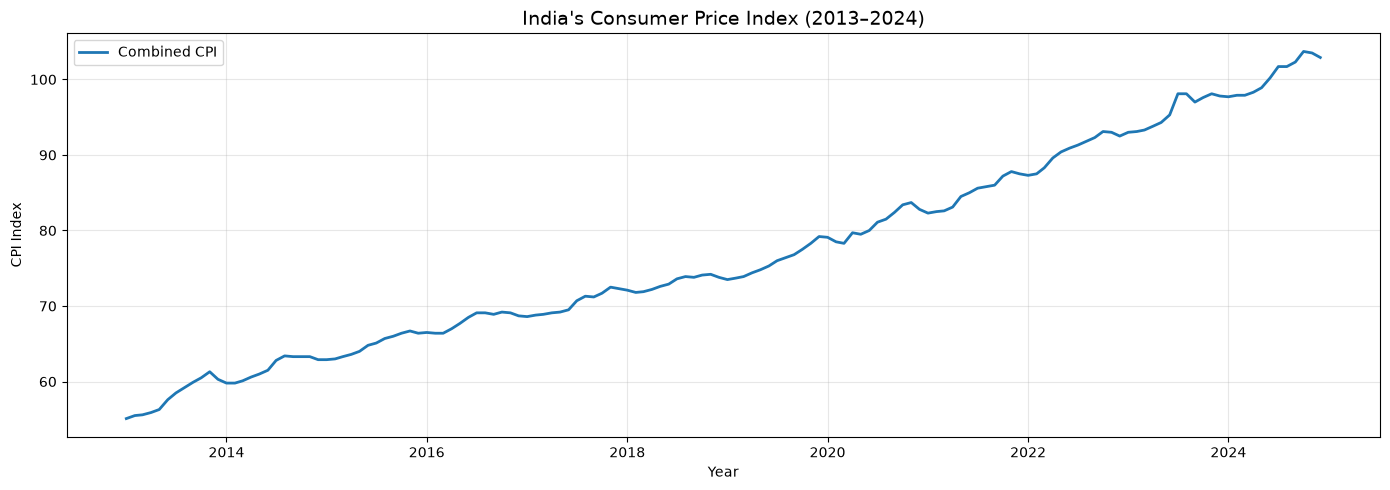

In [11]:
# ==========================================
# 11. CPI INDEX TREND
# ==========================================

plt.figure(figsize=(14, 5))

plt.plot(
    cpi.index,
    cpi["index"],
    linewidth=2,
    label="Combined CPI"
)

plt.title(
    "India's Consumer Price Index (2013–2024)",
    fontsize=14
)

plt.xlabel("Year")
plt.ylabel("CPI Index")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

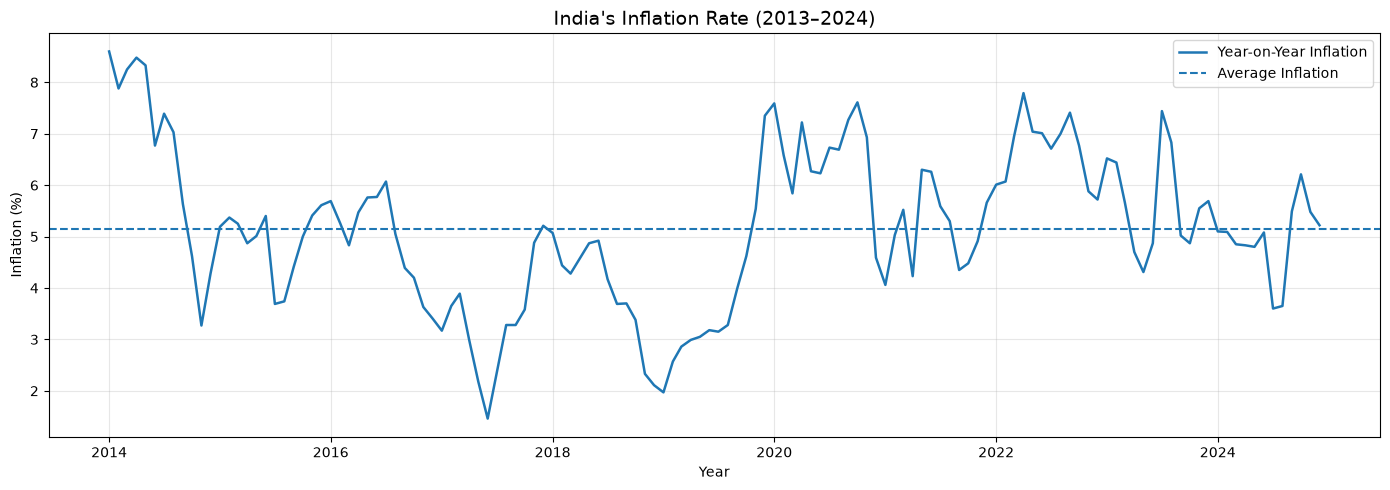

In [12]:
# ==========================================
# 12. INFLATION TREND
# ==========================================

plt.figure(figsize=(14, 5))

plt.plot(
    cpi.index,
    cpi["inflation"],
    linewidth=1.8,
    label="Year-on-Year Inflation"
)

plt.axhline(
    cpi["inflation"].mean(),
    linestyle="--",
    label="Average Inflation"
)

plt.title(
    "India's Inflation Rate (2013–2024)",
    fontsize=14
)

plt.xlabel("Year")
plt.ylabel("Inflation (%)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

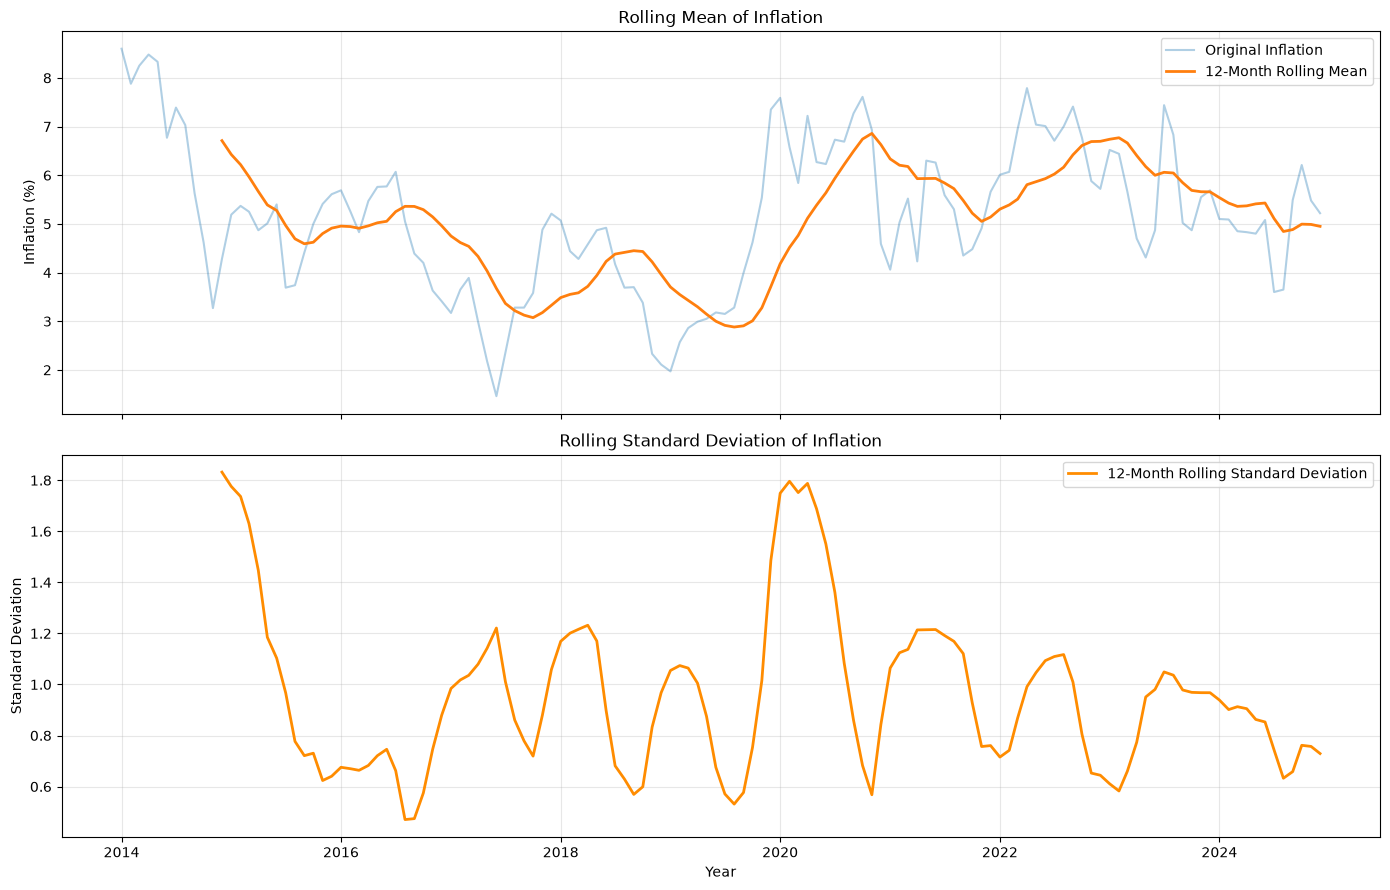

In [13]:
# ==========================================
# 13. ROLLING STATISTICS
# ==========================================

inflation = cpi["inflation"]

rolling_mean = inflation.rolling(window=12).mean()

rolling_std = inflation.rolling(window=12).std()

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 9),
    sharex=True
)

# Rolling mean
axes[0].plot(
    inflation.index,
    inflation,
    alpha=0.35,
    label="Original Inflation"
)

axes[0].plot(
    rolling_mean.index,
    rolling_mean,
    linewidth=2,
    label="12-Month Rolling Mean"
)

axes[0].set_title("Rolling Mean of Inflation")
axes[0].set_ylabel("Inflation (%)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Rolling standard deviation
axes[1].plot(
    rolling_std.index,
    rolling_std,
    color="darkorange",
    linewidth=2,
    label="12-Month Rolling Standard Deviation"
)

axes[1].set_title("Rolling Standard Deviation of Inflation")
axes[1].set_ylabel("Standard Deviation")
axes[1].set_xlabel("Year")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Stationarity Analysis

The stationarity properties of the CPI index and inflation
series are examined using the Augmented Dickey-Fuller
(ADF) and Kwiatkowski-Phillips-Schmidt-Shin (KPSS) tests.

These tests provide complementary evidence regarding
the presence of unit roots and stationarity.

In [14]:
# ==========================================
# 14. AUGMENTED DICKEY-FULLER TEST
# ==========================================

def adf_test(series, name):

    series = series.dropna()

    result = adfuller(
        series,
        autolag="AIC"
    )

    print(f"\nADF Test: {name}")
    print("-" * 45)

    print("ADF Statistic:", result[0])
    print("p-value:", result[1])
    print("Number of Lags:", result[2])
    print("Observations Used:", result[3])

    print("\nCritical Values:")

    for key, value in result[4].items():
        print(f"{key}: {value}")

    if result[1] < 0.05:
        print("\nConclusion: Reject the unit-root null.")
        print("Evidence of stationarity.")
    else:
        print("\nConclusion: Fail to reject the unit-root null.")
        print("Insufficient evidence of stationarity.")


adf_test(cpi["log_cpi"], "Log CPI")

adf_test(cpi["inflation"], "Inflation")


ADF Test: Log CPI
---------------------------------------------
ADF Statistic: 0.2459000751567759
p-value: 0.9747216300968086
Number of Lags: 7
Observations Used: 136

Critical Values:
1%: -3.4793722137854926
5%: -2.8830370378332995
10%: -2.578233635380623

Conclusion: Fail to reject the unit-root null.
Insufficient evidence of stationarity.

ADF Test: Inflation
---------------------------------------------
ADF Statistic: -2.058849790447473
p-value: 0.26137982121912656
Number of Lags: 12
Observations Used: 119

Critical Values:
1%: -3.4865346059036564
5%: -2.8861509858476264
10%: -2.579896092790057

Conclusion: Fail to reject the unit-root null.
Insufficient evidence of stationarity.


/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_2027/2973529420.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_2027/2973529420.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(


In [15]:
# ==========================================
# 15. KPSS TEST
# ==========================================

def kpss_test(series, name):

    series = series.dropna()

    statistic, p_value, lags, critical_values = kpss(
        series,
        regression="c",
        nlags="auto"
    )

    print(f"\nKPSS Test: {name}")
    print("-" * 45)

    print("KPSS Statistic:", statistic)
    print("p-value:", p_value)
    print("Number of Lags:", lags)

    print("\nCritical Values:")

    for key, value in critical_values.items():
        print(f"{key}: {value}")

    if p_value < 0.05:
        print("\nConclusion: Reject the stationarity null.")
        print("Evidence of non-stationarity.")
    else:
        print("\nConclusion: Fail to reject the stationarity null.")
        print("Insufficient evidence against stationarity.")


kpss_test(cpi["log_cpi"], "Log CPI")

kpss_test(cpi["inflation"], "Inflation")


KPSS Test: Log CPI
---------------------------------------------
KPSS Statistic: 1.6975671667278136
p-value: 0.01
Number of Lags: 8

Critical Values:
10%: 0.347
5%: 0.463
2.5%: 0.574
1%: 0.739

Conclusion: Reject the stationarity null.
Evidence of non-stationarity.

KPSS Test: Inflation
---------------------------------------------
KPSS Statistic: 0.2511694227170296
p-value: 0.1
Number of Lags: 6

Critical Values:
10%: 0.347
5%: 0.463
2.5%: 0.574
1%: 0.739

Conclusion: Fail to reject the stationarity null.
Insufficient evidence against stationarity.


/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_2027/3447103619.py:9: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  statistic, p_value, lags, critical_values = kpss(
/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_2027/3447103619.py:9: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, p_value, lags, critical_values = kpss(
/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_2027/3447103619.py:9: InterpolationWarning: The test statistic is outside of the range of p-values available in t

## 6.1 Stationarity Tests with Deterministic Trend

Since the CPI index exhibits a long-term upward trend,
the stationarity tests are extended to include a
deterministic linear trend.

The ADF and KPSS tests are examined under alternative
deterministic specifications to distinguish between
level-stationarity and trend-stationarity.

In [16]:
# ==========================================
# 16. ADF TEST WITH DETERMINISTIC TREND
# ==========================================

def adf_trend_test(series, name):

    series = series.dropna()

    result = adfuller(
        series,
        regression="ct",
        autolag="AIC"
    )

    print(f"\nADF Trend Test: {name}")
    print("-" * 50)

    print("ADF Statistic:", result[0])
    print("p-value:", result[1])
    print("Selected Lags:", result[2])
    print("Observations Used:", result[3])

    print("\nCritical Values:")

    for key, value in result[4].items():
        print(f"{key}: {value}")

    if result[1] < 0.05:
        print("\nReject unit-root null.")
    else:
        print("\nFail to reject unit-root null.")


adf_trend_test(cpi["log_cpi"], "Log CPI")


ADF Trend Test: Log CPI
--------------------------------------------------
ADF Statistic: -1.2899237479778296
p-value: 0.8903983730836554
Selected Lags: 7
Observations Used: 136

Critical Values:
1%: -4.026927225012085
5%: -3.443278929084826
10%: -3.146282869746082

Fail to reject unit-root null.


/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_2027/1356830492.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(


In [17]:
# ==========================================
# 17. KPSS TREND-STATIONARITY TEST
# ==========================================

def kpss_trend_test(series, name):

    series = series.dropna()

    statistic, p_value, lags, critical_values = kpss(
        series,
        regression="ct",
        nlags="auto"
    )

    print(f"\nKPSS Trend Test: {name}")
    print("-" * 50)

    print("KPSS Statistic:", statistic)
    print("p-value:", p_value)
    print("Selected Lags:", lags)

    print("\nCritical Values:")

    for key, value in critical_values.items():
        print(f"{key}: {value}")

    if p_value < 0.05:
        print("\nReject trend-stationarity null.")
    else:
        print("\nFail to reject trend-stationarity null.")


kpss_trend_test(cpi["log_cpi"], "Log CPI")


KPSS Trend Test: Log CPI
--------------------------------------------------
KPSS Statistic: 0.26815317788446436
p-value: 0.01
Selected Lags: 8

Critical Values:
10%: 0.119
5%: 0.146
2.5%: 0.176
1%: 0.216

Reject trend-stationarity null.


/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_2027/382487034.py:9: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  statistic, p_value, lags, critical_values = kpss(
/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_2027/382487034.py:9: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, p_value, lags, critical_values = kpss(


## 6.2 First-Difference Stationarity Analysis

Since the log CPI series exhibits evidence of non-stationarity,
we examine its first difference to determine whether the
transformed series is stationary.

The ADF and KPSS tests are applied to the differenced series.

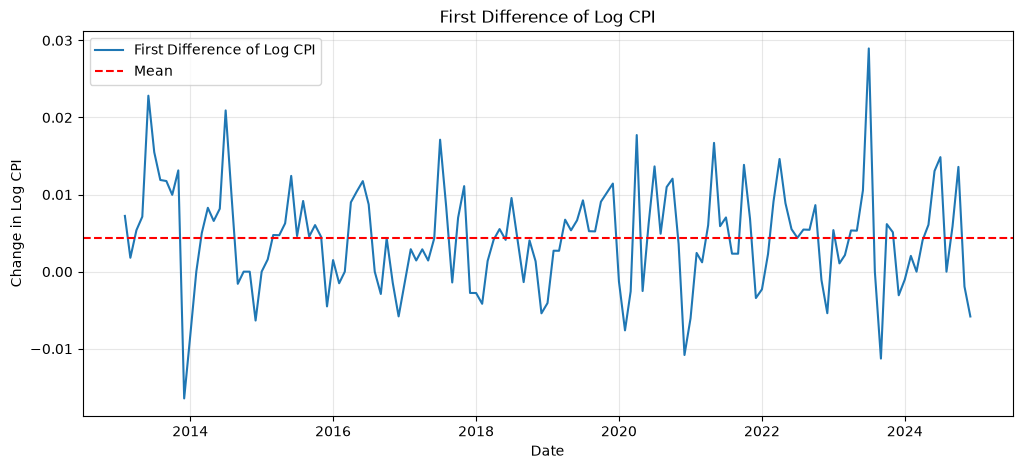

In [18]:
# First difference of log CPI
cpi["d_log_cpi"] = cpi["log_cpi"].diff()

# Convert to approximate monthly percentage change
cpi["monthly_cpi_change"] = cpi["d_log_cpi"] * 100

# Plot the first-differenced series
plt.figure(figsize=(12, 5))

plt.plot(
    cpi.index,
    cpi["d_log_cpi"],
    label="First Difference of Log CPI"
)

plt.axhline(
    cpi["d_log_cpi"].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

plt.title("First Difference of Log CPI")
plt.xlabel("Date")
plt.ylabel("Change in Log CPI")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [19]:
# ADF test
adf_test(cpi["d_log_cpi"], "First Difference of Log CPI")

# KPSS test
kpss_test(cpi["d_log_cpi"], "First Difference of Log CPI")


ADF Test: First Difference of Log CPI
---------------------------------------------
ADF Statistic: -8.32123814648868
p-value: 3.567892345960882e-13
Number of Lags: 6
Observations Used: 136

Critical Values:
1%: -3.4793722137854926
5%: -2.8830370378332995
10%: -2.578233635380623

Conclusion: Reject the unit-root null.
Evidence of stationarity.

KPSS Test: First Difference of Log CPI
---------------------------------------------
KPSS Statistic: 0.056917217968153154
p-value: 0.1
Number of Lags: 2

Critical Values:
10%: 0.347
5%: 0.463
2.5%: 0.574
1%: 0.739

Conclusion: Fail to reject the stationarity null.
Insufficient evidence against stationarity.


/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_2027/2973529420.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_2027/3447103619.py:9: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  statistic, p_value, lags, critical_values = kpss(
/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_2027/3447103619.py:9: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In r

## 7. Time-Series Diagnostics

The autocorrelation structure of the CPI series is examined
before structural-break estimation.

The ACF and PACF plots are used to understand temporal
dependence, while the Ljung-Box test evaluates whether
autocorrelations are jointly significant.

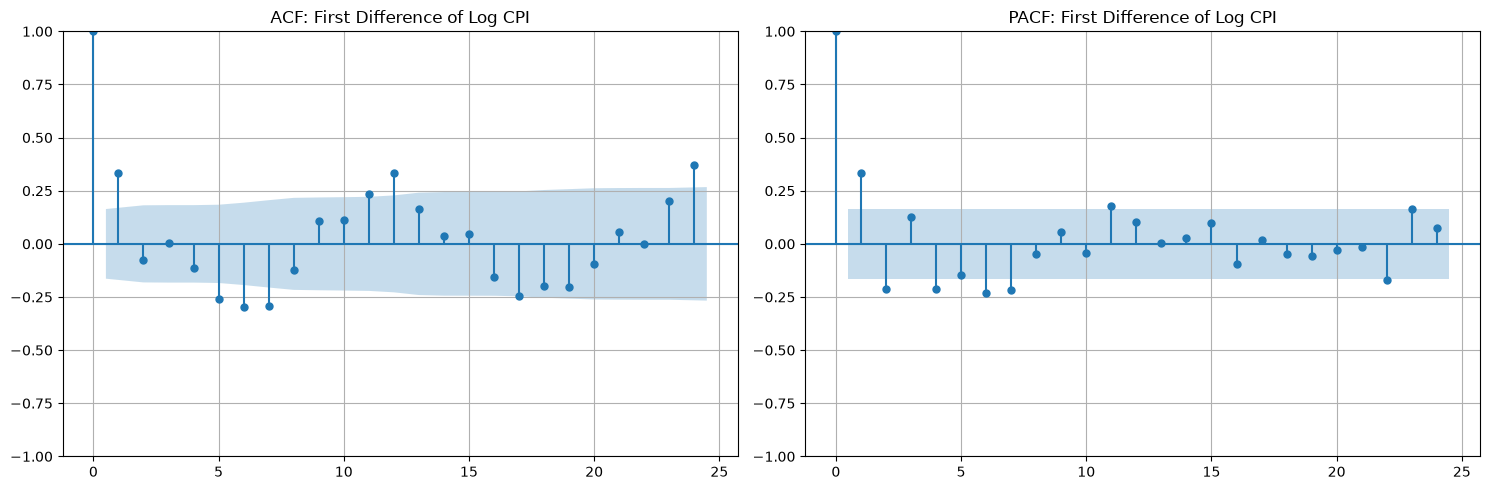

In [20]:
# ACF and PACF of first-differenced log CPI

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_acf(
    cpi["d_log_cpi"].dropna(),
    lags=24,
    ax=axes[0]
)

axes[0].set_title("ACF: First Difference of Log CPI")

plot_pacf(
    cpi["d_log_cpi"].dropna(),
    lags=24,
    ax=axes[1],
    method="ywm"
)

axes[1].set_title("PACF: First Difference of Log CPI")

plt.tight_layout()
plt.show()

In [21]:
ljung_box_results = acorr_ljungbox(
    cpi["d_log_cpi"].dropna(),
    lags=[6, 12, 18, 24],
    return_df=True
)

display(ljung_box_results)

,lb_stat,lb_pvalue
6,42.549686,1.431946e-07
12,88.379014,1.016173e-13
18,113.656398,6.536121e-16
24,153.547395,7.242398e-21


## 7.1 Baseline Trend Regression and Residual Diagnostics

A linear time-trend regression is estimated for the log CPI
series to examine deviations from its long-term trajectory.

The residuals are examined using ACF, PACF and the
Ljung-Box test to identify remaining serial dependence.

In [22]:
# Create a time index
cpi["time"] = np.arange(len(cpi))

# Estimate baseline linear trend model
X_trend = sm.add_constant(cpi["time"])

trend_model = sm.OLS(
    cpi["log_cpi"],
    X_trend
).fit()

# Store residuals
cpi["trend_residuals"] = trend_model.resid

# Display regression summary
print(trend_model.summary())

                            OLS Regression Results                            
Dep. Variable:                log_cpi   R-squared:                       0.990
Model:                            OLS   Adj. R-squared:                  0.990
Method:                 Least Squares   F-statistic:                 1.429e+04
Date:                Thu, 05 Nov 2026   Prob (F-statistic):          2.12e-144
Time:                        20:23:57   Log-Likelihood:                 383.57
No. Observations:                 144   AIC:                            -763.1
Df Residuals:                     142   BIC:                            -757.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.0391      0.003   1434.502      0.0

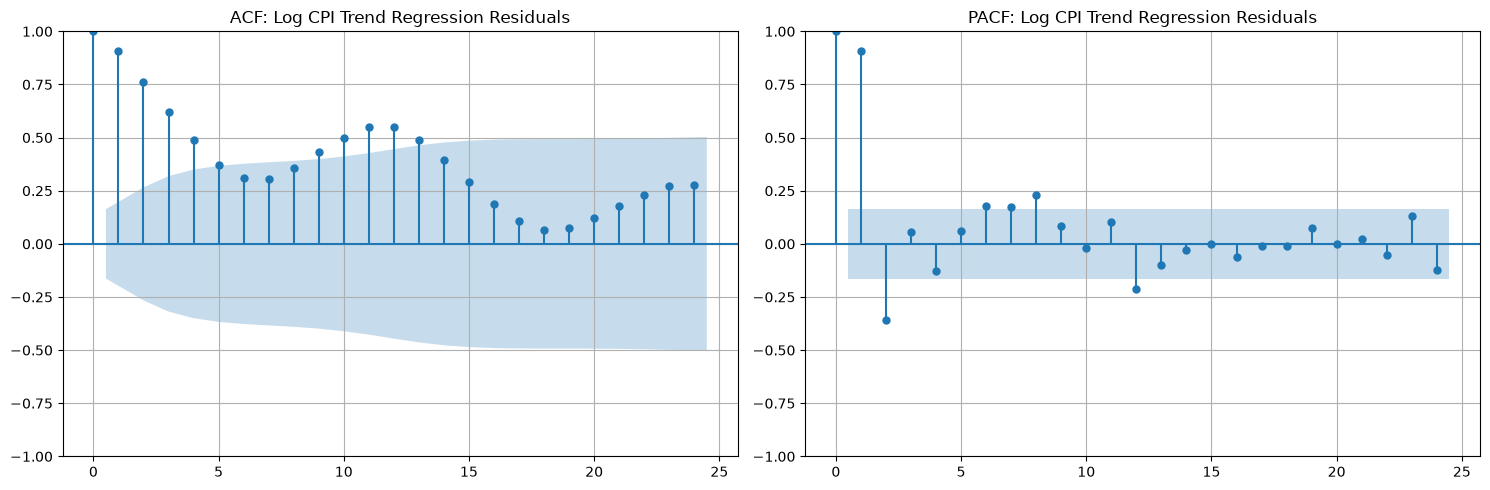

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_acf(
    cpi["trend_residuals"],
    lags=24,
    ax=axes[0]
)

axes[0].set_title("ACF: Log CPI Trend Regression Residuals")

plot_pacf(
    cpi["trend_residuals"],
    lags=24,
    ax=axes[1],
    method="ywm"
)

axes[1].set_title("PACF: Log CPI Trend Regression Residuals")

plt.tight_layout()
plt.show()

In [24]:
residual_lb = acorr_ljungbox(
    cpi["trend_residuals"],
    lags=[6, 12, 18, 24],
    return_df=True
)

display(residual_lb)

,lb_stat,lb_pvalue
6,335.788626,1.732374e-69
12,534.940424,8.026436e-107
18,620.184968,4.637333e-120
24,664.654981,6.647377e-125


## 7.2 Baseline Regression for Monthly CPI Growth

Since the first difference of log CPI is stationary,
a regression model is estimated using monthly CPI growth.

Newey-West HAC standard errors are used to account
for potential heteroskedasticity and autocorrelation
in the regression errors.

In [25]:
# Dependent variable: first difference of log CPI
growth = cpi["d_log_cpi"].dropna()

# Time index aligned with the differenced observations
time_index = np.arange(len(cpi))[1:]

X_growth = sm.add_constant(time_index)

# Estimate OLS with HAC covariance
growth_model = sm.OLS(
    growth.values,
    X_growth
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 12}
)

print(growth_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.006
Method:                 Least Squares   F-statistic:                    0.1825
Date:                Thu, 05 Nov 2026   Prob (F-statistic):              0.670
Time:                        20:26:27   Log-Likelihood:                 512.27
No. Observations:                 143   AIC:                            -1021.
Df Residuals:                     141   BIC:                            -1015.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0047      0.001      4.141      0.0

In [26]:
# Prepare the monthly CPI growth dataset
growth_data = cpi.loc[
    cpi["d_log_cpi"].notna(),
    ["d_log_cpi"]
].copy()

# Define the candidate structural-break date
break_date = pd.Timestamp("2020-04-01")

# Create time index
growth_data["time"] = np.arange(len(growth_data))

# Create post-break dummy
growth_data["post"] = (
    growth_data.index >= break_date
).astype(int)

# Identify the first post-break observation
break_index = np.where(growth_data["post"] == 1)[0][0]

# Create post-break time interaction
growth_data["post_time"] = (
    growth_data["post"] *
    (growth_data["time"] - break_index)
)

# Display break information
print("Candidate Break Date:", break_date.date())
print("First Post-Break Observation:", growth_data.index[break_index].date())
print("Observations Before Break:", (growth_data["post"] == 0).sum())
print("Observations After Break:", (growth_data["post"] == 1).sum())

display(growth_data.loc["2020-01-01":"2020-08-01"])

Candidate Break Date: 2020-04-01
First Post-Break Observation: 2020-04-01
Observations Before Break: 86
Observations After Break: 57


,d_log_cpi,time,post,post_time
date,,,,
2020-01-01,-0.001263,83,0,0
2020-02-01,-0.007614,84,0,0
2020-03-01,-0.002551,85,0,0
2020-04-01,0.017722,86,1,0
2020-05-01,-0.002513,87,1,1
2020-06-01,0.006270,88,1,2
2020-07-01,0.013656,89,1,3
2020-08-01,0.004920,90,1,4


In [27]:
# Dependent variable
y = growth_data["d_log_cpi"]

# Independent variables
X = growth_data[
    ["time", "post", "post_time"]
]

X = sm.add_constant(X)

# Estimate segmented regression with HAC covariance
break_model = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 12}
)

print(break_model.summary())

                            OLS Regression Results                            
Dep. Variable:              d_log_cpi   R-squared:                       0.023
Model:                            OLS   Adj. R-squared:                  0.002
Method:                 Least Squares   F-statistic:                     1.962
Date:                Thu, 05 Nov 2026   Prob (F-statistic):              0.123
Time:                        20:29:27   Log-Likelihood:                 513.84
No. Observations:                 143   AIC:                            -1020.
Df Residuals:                     139   BIC:                            -1008.
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0060      0.001      4.280      0.0

In [28]:
# Joint hypothesis:
# H0: post = 0 and post_time = 0

R = np.array([
    [0, 0, 1, 0],
    [0, 0, 0, 1]
])

wald_result = break_model.wald_test(
    R,
    use_f=False
)

print("HAC-Robust Joint Wald Test")
print("-" * 45)
print("Test Statistic:", float(wald_result.statistic))
print("p-value:", float(wald_result.pvalue))
print("Degrees of Freedom:", wald_result.df_denom if hasattr(wald_result, "df_denom") else 2)

if wald_result.pvalue < 0.05:
    print("\nReject H0: Evidence of a structural change.")
else:
    print("\nFail to reject H0: Insufficient evidence of a structural change.")

HAC-Robust Joint Wald Test
---------------------------------------------
Test Statistic: 5.805547432331718
p-value: 0.05487081272648871
Degrees of Freedom: 2.0

Fail to reject H0: Insufficient evidence of a structural change.


In [29]:
def dynamic_programming_breaks(y, x, min_segment=30, max_breaks=4):

    y = np.asarray(y, dtype=float)
    x = np.asarray(x, dtype=float)

    n = len(y)

    # Maximum feasible number of segments
    max_segments = min(max_breaks + 1, n // min_segment)

    # Precompute SSR for every possible segment
    ssr = np.full((n, n + 1), np.inf)

    for start in range(n):
        for end in range(start + min_segment, n + 1):

            X_segment = np.column_stack([
                np.ones(end - start),
                x[start:end]
            ])

            y_segment = y[start:end]

            coefficients = np.linalg.lstsq(
                X_segment,
                y_segment,
                rcond=None
            )[0]

            residuals = y_segment - X_segment @ coefficients

            ssr[start, end] = np.sum(residuals ** 2)

    # Dynamic programming tables
    dp = np.full((max_segments + 1, n + 1), np.inf)
    previous = np.full(
        (max_segments + 1, n + 1),
        -1,
        dtype=int
    )

    # One-segment solution
    for end in range(min_segment, n + 1):
        dp[1, end] = ssr[0, end]

    # Multiple-segment solutions
    for segments in range(2, max_segments + 1):

        for end in range(segments * min_segment, n + 1):

            for start in range(
                (segments - 1) * min_segment,
                end - min_segment + 1
            ):

                candidate = (
                    dp[segments - 1, start]
                    + ssr[start, end]
                )

                if candidate < dp[segments, end]:
                    dp[segments, end] = candidate
                    previous[segments, end] = start

    # Calculate BIC for each feasible segmentation
    results = []

    for segments in range(1, max_segments + 1):

        total_ssr = dp[segments, n]

        breaks = segments - 1
        parameters = 2 * segments + breaks

        bic = (
            n * np.log(total_ssr / n)
            + parameters * np.log(n)
        )

        # Recover break positions
        break_positions = []
        end = n

        for s in range(segments, 1, -1):
            start = previous[s, end]
            break_positions.append(start)
            end = start

        break_positions.reverse()

        results.append({
            "segments": segments,
            "breaks": breaks,
            "SSR": total_ssr,
            "BIC": bic,
            "break_positions": break_positions
        })

    return pd.DataFrame(results)

In [30]:
# Apply dynamic programming to monthly CPI growth

dp_results = dynamic_programming_breaks(
    y=growth_data["d_log_cpi"].values,
    x=growth_data["time"].values,
    min_segment=30,
    max_breaks=4
)

# Display BIC comparison
display(
    dp_results[
        ["segments", "breaks", "SSR", "BIC"]
    ]
)

,segments,breaks,SSR,BIC
0,1,0,0.006476,-1420.436671
1,2,1,0.006233,-1411.020244
2,3,2,0.006156,-1397.893220
3,4,3,0.006105,-1384.195202


In [31]:
# Select the model with the lowest BIC
best_model = dp_results.loc[
    dp_results["BIC"].idxmin()
]

print("Optimal Number of Breaks:", best_model["breaks"])
print("Optimal Number of Segments:", best_model["segments"])
print("Minimum BIC:", best_model["BIC"])

# Convert break positions into calendar dates
estimated_break_positions = best_model["break_positions"]

estimated_break_dates = [
    growth_data.index[position]
    for position in estimated_break_positions
]

print("\nEstimated Structural Break Dates:")

if estimated_break_dates:
    for date in estimated_break_dates:
        print(date.strftime("%B %Y"))
else:
    print("No structural breaks detected.")

Optimal Number of Breaks: 0
Optimal Number of Segments: 1
Minimum BIC: -1420.4366711948314

Estimated Structural Break Dates:
No structural breaks detected.


### 9.1.1 Visualisation of the Selected Segmentation

The BIC-selected model contains one segment and no
structural breakpoints.

The observed monthly CPI growth series is plotted
alongside its fitted linear trend.

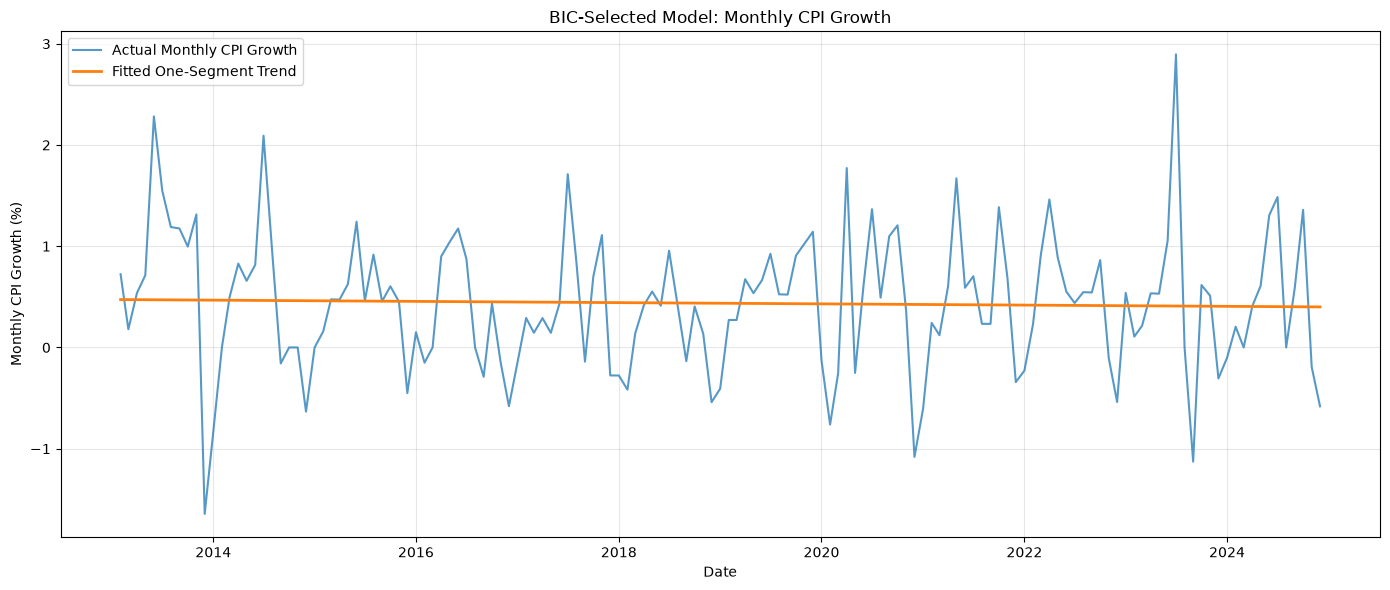

In [32]:
# Estimate the selected one-segment regression
X_single = sm.add_constant(growth_data["time"])

single_model = sm.OLS(
    growth_data["d_log_cpi"],
    X_single
).fit()

growth_data["fitted_growth"] = single_model.fittedvalues

# Plot actual and fitted values
plt.figure(figsize=(14, 6))

plt.plot(
    growth_data.index,
    growth_data["d_log_cpi"] * 100,
    label="Actual Monthly CPI Growth",
    alpha=0.75
)

plt.plot(
    growth_data.index,
    growth_data["fitted_growth"] * 100,
    label="Fitted One-Segment Trend",
    linewidth=2
)

plt.title("BIC-Selected Model: Monthly CPI Growth")
plt.xlabel("Date")
plt.ylabel("Monthly CPI Growth (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Comparative Analysis

The results obtained from the pre-specified Chow-style
test and unknown-break dynamic programming method
are compared.

The objective is to assess whether both approaches
provide consistent evidence regarding structural
changes in monthly CPI growth.

In [33]:
comparison = pd.DataFrame({
    "Method": [
        "HAC-Robust Chow-Style Wald Test",
        "Dynamic Programming + BIC"
    ],
    "Break Specification": [
        "Pre-specified: April 2020",
        "Unknown break locations"
    ],
    "Estimated Breaks": [
        1,
        int(best_model["breaks"])
    ],
    "Test Statistic / Criterion": [
        float(wald_result.statistic),
        float(best_model["BIC"])
    ],
    "p-value": [
        float(wald_result.pvalue),
        np.nan
    ],
    "Conclusion": [
        "Not significant at 5%",
        "One segment preferred"
    ]
})

display(comparison)

,Method,Break Specification,Estimated Breaks,Test Statistic / Criterion,p-value,Conclusion
0,HAC-Robust Chow-Style Wald Test,Pre-specified: April 2020,1,5.805547,0.054871,Not significant at 5%
1,Dynamic Programming + BIC,Unknown break locations,0,-1420.436671,NaN,One segment preferred


## 11.1 Sensitivity to Minimum Segment Length

The dynamic programming segmentation procedure is
re-estimated using alternative minimum segment lengths.

The purpose is to examine whether the selected number
of structural breaks is sensitive to the minimum
number of observations permitted in each segment.

In [34]:
min_segment_values = [24, 30, 36]

sensitivity_results = []

for min_seg in min_segment_values:

    result = dynamic_programming_breaks(
        y=growth_data["d_log_cpi"].values,
        x=growth_data["time"].values,
        min_segment=min_seg,
        max_breaks=4
    )

    best = result.loc[result["BIC"].idxmin()]

    sensitivity_results.append({
        "Minimum Segment Length": min_seg,
        "Selected Breaks": int(best["breaks"]),
        "Selected Segments": int(best["segments"]),
        "SSR": best["SSR"],
        "BIC": best["BIC"]
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df)

,Minimum Segment Length,Selected Breaks,Selected Segments,SSR,BIC
0,24,0,1,0.006476,-1420.436671
1,30,0,1,0.006476,-1420.436671
2,36,0,1,0.006476,-1420.436671


## 11.2 Sensitivity to Regression Specification

The segmentation procedure is repeated using an
intercept-only model.

Unlike the baseline model, which allows both
intercept and slope changes, this specification
allows only the segment-specific mean to change.

The results are compared to evaluate whether
the selected number of breaks depends on the
regression specification.

In [35]:
def dynamic_programming_intercept(y, min_segment=30, max_breaks=4):

    y = np.asarray(y, dtype=float)
    n = len(y)

    max_segments = min(max_breaks + 1, n // min_segment)

    ssr = np.full((n, n + 1), np.inf)

    # Precompute segment SSR using segment-specific means
    for start in range(n):
        for end in range(start + min_segment, n + 1):

            segment = y[start:end]
            ssr[start, end] = np.sum(
                (segment - segment.mean()) ** 2
            )

    dp = np.full((max_segments + 1, n + 1), np.inf)
    previous = np.full(
        (max_segments + 1, n + 1),
        -1,
        dtype=int
    )

    for end in range(min_segment, n + 1):
        dp[1, end] = ssr[0, end]

    for segments in range(2, max_segments + 1):

        for end in range(segments * min_segment, n + 1):

            for start in range(
                (segments - 1) * min_segment,
                end - min_segment + 1
            ):

                candidate = dp[segments - 1, start] + ssr[start, end]

                if candidate < dp[segments, end]:
                    dp[segments, end] = candidate
                    previous[segments, end] = start

    results = []

    for segments in range(1, max_segments + 1):

        total_ssr = dp[segments, n]
        breaks = segments - 1

        # One mean per segment + break locations
        parameters = segments + breaks

        bic = (
            n * np.log(total_ssr / n)
            + parameters * np.log(n)
        )

        break_positions = []
        end = n

        for s in range(segments, 1, -1):
            start = previous[s, end]
            break_positions.append(start)
            end = start

        break_positions.reverse()

        results.append({
            "segments": segments,
            "breaks": breaks,
            "SSR": total_ssr,
            "BIC": bic,
            "break_positions": break_positions
        })

    return pd.DataFrame(results)

In [36]:
# Intercept-only segmentation
intercept_results = dynamic_programming_intercept(
    y=growth_data["d_log_cpi"].values,
    min_segment=30,
    max_breaks=4
)

display(
    intercept_results[
        ["segments", "breaks", "SSR", "BIC"]
    ]
)

# Identify preferred model
best_intercept = intercept_results.loc[
    intercept_results["BIC"].idxmin()
]

print("Selected Breaks:", best_intercept["breaks"])
print("Selected Segments:", best_intercept["segments"])
print("Minimum BIC:", best_intercept["BIC"])

,segments,breaks,SSR,BIC
0,1,0,0.006482,-1425.259965
1,2,1,0.006411,-1416.905764
2,3,2,0.006261,-1410.379475
3,4,3,0.006237,-1400.990105


Selected Breaks: 0
Selected Segments: 1
Minimum BIC: -1425.2599651785094


## 11.3 Serial-Correlation Robustness

The residuals of the BIC-selected one-segment model
are examined for serial correlation.

Additionally, conventional OLS standard errors are
compared with Newey-West HAC standard errors to
evaluate the effect of serial dependence on statistical
inference.

In [37]:
# Baseline one-segment regression
X_baseline = sm.add_constant(growth_data["time"])
y_baseline = growth_data["d_log_cpi"]

# Conventional OLS
ols_conventional = sm.OLS(
    y_baseline,
    X_baseline
).fit()

# HAC-robust OLS
ols_hac = sm.OLS(
    y_baseline,
    X_baseline
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 12}
)

# Compare coefficients and standard errors
standard_error_comparison = pd.DataFrame({
    "Coefficient": ols_conventional.params,
    "OLS Std Error": ols_conventional.bse,
    "HAC Std Error": ols_hac.bse,
    "OLS p-value": ols_conventional.pvalues,
    "HAC p-value": ols_hac.pvalues
})

display(standard_error_comparison)

,Coefficient,OLS Std Error,HAC Std Error,OLS p-value,HAC p-value
const,0.004730,0.001128,0.001132,0.000048,0.000029
time,-0.000005,0.000014,0.000012,0.711169,0.669198


In [38]:
# Residuals from the baseline model
baseline_residuals = ols_conventional.resid

# Ljung-Box test
serial_test = acorr_ljungbox(
    baseline_residuals,
    lags=[6, 12, 18, 24],
    return_df=True
)

display(serial_test)

,lb_stat,lb_pvalue
6,42.485006,1.474730e-07
12,88.591727,9.244252e-14
18,113.538255,6.877520e-16
24,153.487320,7.431655e-21


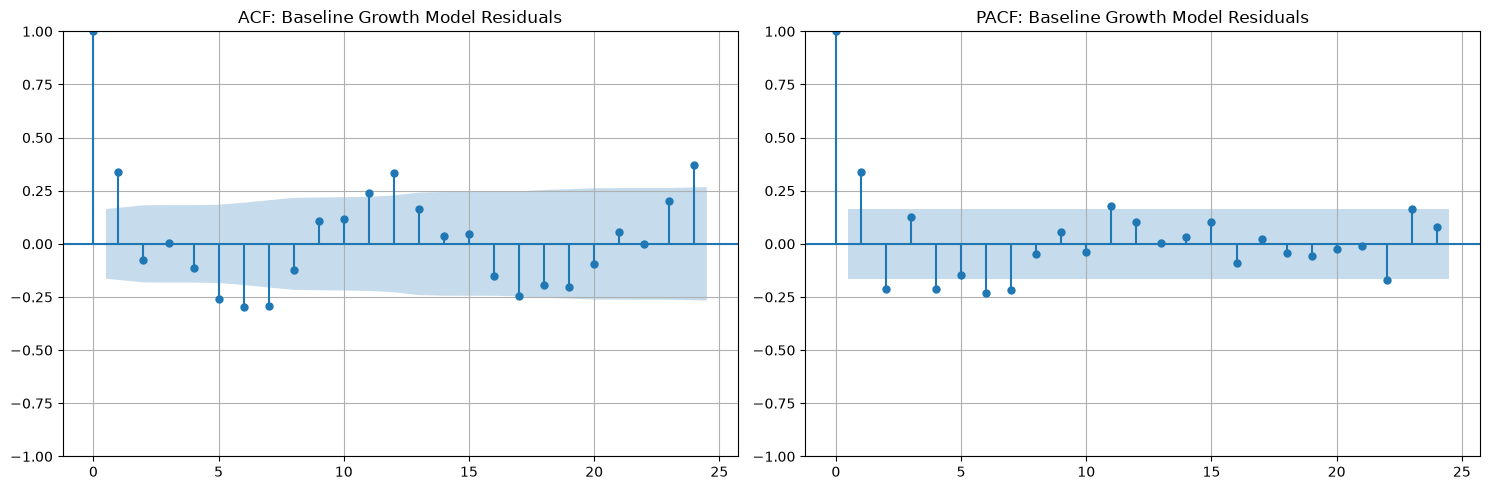

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_acf(
    baseline_residuals,
    lags=24,
    ax=axes[0]
)

axes[0].set_title("ACF: Baseline Growth Model Residuals")

plot_pacf(
    baseline_residuals,
    lags=24,
    ax=axes[1],
    method="ywm"
)

axes[1].set_title("PACF: Baseline Growth Model Residuals")

plt.tight_layout()
plt.show()

## 11.4 Autoregressive Modelling of CPI Growth

An autoregressive model is estimated to investigate
the serial dependence in monthly CPI growth.

Alternative lag specifications are compared using
the Akaike Information Criterion (AIC) and Bayesian
Information Criterion (BIC).

The residuals of the selected model are subsequently
examined for remaining autocorrelation.

In [43]:
from statsmodels.tsa.ar_model import AutoReg

growth_series = growth_data["d_log_cpi"].dropna()

ar_results = []

for lag in range(1, 13):

    model = AutoReg(
        growth_series,
        lags=lag,
        trend="c"
    ).fit()

    ar_results.append({
        "AR Order": lag,
        "AIC": model.aic,
        "BIC": model.bic
    })

ar_comparison = pd.DataFrame(ar_results)

display(ar_comparison)

/Users/ananyosen/STRUCTURAL-BREAKS/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/ananyosen/STRUCTURAL-BREAKS/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/ananyosen/STRUCTURAL-BREAKS/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/ananyosen/STRUCTURAL-BREAKS/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/ananyosen/STRUCTURAL-BREAKS/.venv/lib/python3.14/site-package

,AR Order,AIC,BIC
0,1,-1027.729917,-1018.862436
1,2,-1024.259962,-1012.464923
2,3,-1016.281927,-1001.573715
3,4,-1012.459143,-994.852300
4,5,-1015.158279,-994.667503
5,6,-1014.053615,-990.693768
6,7,-1015.142792,-988.928898
7,8,-1007.447476,-978.394728
8,9,-1000.043854,-968.167616
9,10,-999.071225,-964.387036


In [45]:
best_ar_order = int(
    ar_comparison.loc[
        ar_comparison["BIC"].idxmin(),
        "AR Order"
    ]
)

print("Selected AR Order:", best_ar_order)

ar_model = AutoReg(
    growth_series,
    lags=best_ar_order,
    trend="c"
).fit()

print(ar_model.summary())

Selected AR Order: 1
                            AutoReg Model Results                             
Dep. Variable:              d_log_cpi   No. Observations:                  142
Model:                     AutoReg(1)   Log Likelihood                 516.865
Method:               Conditional MLE   S.D. of innovations              0.006
Date:                Thu, 05 Nov 2026   AIC                          -1027.730
Time:                        20:43:29   BIC                          -1018.862
Sample:                    03-01-2013   HQIC                         -1024.127
                         - 12-01-2024                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0028      0.001      4.430      0.000       0.002       0.004
d_log_cpi.L1     0.3412      0.080      4.290      0.000       0.185       0.497
                       

/Users/ananyosen/STRUCTURAL-BREAKS/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [ ]:
ar_residuals = ar_model.resid

ar_ljung_box = acorr_ljungbox(
    ar_residuals,
    lags=[6, 12, 18, 24],
    return_df=True
)

display(ar_ljung_box)

,lb_stat,lb_pvalue
6,17.479217,7.674384e-03
12,42.583809,2.655215e-05
18,53.356569,2.310342e-05
24,80.482406,5.096422e-08


In [47]:
from statsmodels.tsa.ar_model import AutoReg

ar_seasonal = AutoReg(
    growth_series,
    lags=[1, 12],
    trend="c"
).fit()

print(ar_seasonal.summary())

                            AutoReg Model Results                             
Dep. Variable:              d_log_cpi   No. Observations:                  131
Model:             Restr. AutoReg(12)   Log Likelihood                 492.663
Method:               Conditional MLE   S.D. of innovations              0.006
Date:                Thu, 05 Nov 2026   AIC                           -977.327
Time:                        20:44:44   BIC                           -965.826
Sample:                    02-01-2014   HQIC                          -972.653
                         - 12-01-2024                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.0019      0.001      2.970      0.003       0.001       0.003
d_log_cpi.L1      0.2203      0.081      2.730      0.006       0.062       0.379
d_log_cpi.L12     0.3077      0.075     

/Users/ananyosen/STRUCTURAL-BREAKS/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [48]:
seasonal_residuals = ar_seasonal.resid

seasonal_lb = acorr_ljungbox(
    seasonal_residuals,
    lags=[6, 12, 18, 24],
    return_df=True
)

display(seasonal_lb)

,lb_stat,lb_pvalue
6,15.496781,0.016726
12,23.151397,0.026468
18,29.419964,0.043482
24,42.919390,0.010160


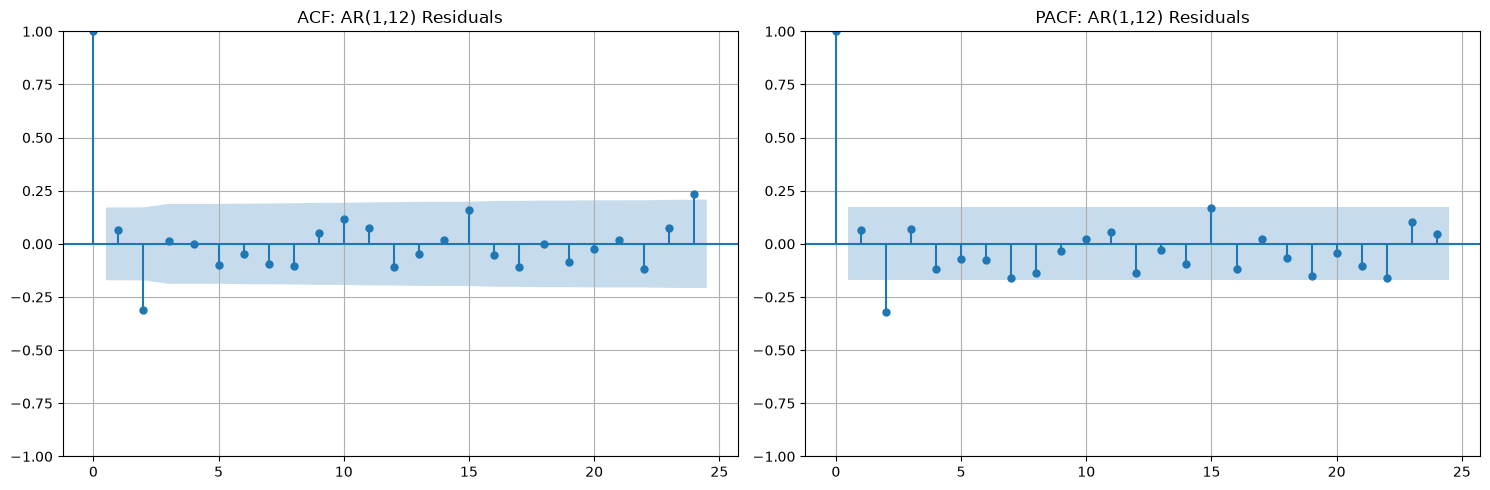

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_acf(
    seasonal_residuals,
    lags=24,
    ax=axes[0]
)

axes[0].set_title("ACF: AR(1,12) Residuals")

plot_pacf(
    seasonal_residuals,
    lags=24,
    ax=axes[1],
    method="ywm"
)

axes[1].set_title("PACF: AR(1,12) Residuals")

plt.tight_layout()
plt.show()

In [50]:
# Adjust Ljung-Box degrees of freedom
ar_lags_adjusted = acorr_ljungbox(
    seasonal_residuals,
    lags=[6, 12, 18, 24],
    model_df=2,
    return_df=True
)

display(ar_lags_adjusted)

,lb_stat,lb_pvalue
6,15.496781,0.003774
12,23.151397,0.010201
18,29.419964,0.021253
24,42.919390,0.004828


### 11.5 Summary of Serial-Correlation Diagnostics

The serial dependence in monthly CPI growth is examined
using baseline regression residuals and alternative
autoregressive specifications.

The objective is to assess whether autoregressive
modelling adequately captures the temporal dependence
in the series.

In [51]:
serial_summary = pd.DataFrame({
    "Model": [
        "Baseline Linear Regression",
        "AR(1)",
        "AR(1,12)"
    ],
    "Ljung-Box p-value (Lag 6)": [
        1.474730e-07,
        7.674384e-03,
        3.774000e-03
    ],
    "Ljung-Box p-value (Lag 12)": [
        9.244252e-14,
        2.655215e-05,
        1.020100e-02
    ],
    "Residual Autocorrelation": [
        "Present",
        "Present",
        "Present"
    ]
})

display(serial_summary)

,Model,Ljung-Box p-value (Lag 6),Ljung-Box p-value (Lag 12),Residual Autocorrelation
0,Baseline Linear Regression,1.474730e-07,9.244252e-14,Present
1,AR(1),7.674384e-03,2.655215e-05,Present
2,"AR(1,12)",3.774000e-03,1.020100e-02,Present


In [52]:
diagnostic_models = {
    "Baseline": (baseline_residuals, 0),
    "AR(1)": (ar_model.resid, 1),
    "AR(1,12)": (seasonal_residuals, 2)
}

diagnostic_results = []

for name, (residuals, model_df) in diagnostic_models.items():

    lb = acorr_ljungbox(
        residuals,
        lags=[6, 12, 18, 24],
        model_df=model_df,
        return_df=True
    )

    for lag in [6, 12, 18, 24]:
        diagnostic_results.append({
            "Model": name,
            "Lag": lag,
            "Ljung-Box Statistic": lb.loc[lag, "lb_stat"],
            "Adjusted p-value": lb.loc[lag, "lb_pvalue"]
        })

diagnostic_comparison = pd.DataFrame(diagnostic_results)

display(diagnostic_comparison)

,Model,Lag,Ljung-Box Statistic,Adjusted p-value
0,Baseline,6,42.485006,1.474730e-07
1,Baseline,12,88.591727,9.244252e-14
2,Baseline,18,113.538255,6.877520e-16
3,Baseline,24,153.487320,7.431655e-21
4,AR(1),6,17.479217,3.675153e-03
5,AR(1),12,42.583809,1.282988e-05
6,AR(1),18,53.356569,1.254175e-05
7,AR(1),24,80.482406,2.652021e-08
8,"AR(1,12)",6,15.496781,3.774373e-03
9,"AR(1,12)",12,23.151397,1.020133e-02


## 12. Final Empirical Results and Interpretation

The findings from the stationarity analysis, structural-break
tests, dynamic programming estimation and robustness
investigations are consolidated.

The results are interpreted in the context of India's
monthly Consumer Price Index (CPI) data from January
2013 to December 2024.

In [53]:
final_results = pd.DataFrame({
    "Analysis": [
        "ADF and KPSS: Log CPI",
        "ADF and KPSS: First Difference",
        "April 2020 HAC-Wald Test",
        "DP/BIC: Intercept and Slope",
        "DP/BIC: Intercept Only",
        "Minimum Segment Sensitivity",
        "Serial Correlation Diagnostics"
    ],
    "Finding": [
        "Non-stationary",
        "Stationary",
        "p-value = 0.0549",
        "0 breaks",
        "0 breaks",
        "0 breaks for lengths 24, 30, 36",
        "Significant autocorrelation persists"
    ],
    "Interpretation": [
        "Log CPI is plausibly I(1)",
        "First difference is plausibly I(0)",
        "Not significant at 5%",
        "One segment preferred",
        "One segment preferred",
        "Stable across tested lengths",
        "Error dependence remains"
    ]
})

display(final_results)

,Analysis,Finding,Interpretation
0,ADF and KPSS: Log CPI,Non-stationary,Log CPI is plausibly I(1)
1,ADF and KPSS: First Difference,Stationary,First difference is plausibly I(0)
2,April 2020 HAC-Wald Test,p-value = 0.0549,Not significant at 5%
3,DP/BIC: Intercept and Slope,0 breaks,One segment preferred
4,DP/BIC: Intercept Only,0 breaks,One segment preferred
5,Minimum Segment Sensitivity,"0 breaks for lengths 24, 30, 36",Stable across tested lengths
6,Serial Correlation Diagnostics,Significant autocorrelation persists,Error dependence remains


In [54]:
# Create output directory
TABLE_DIR = BASE_DIR / "outputs" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Save results
final_results.to_csv(
    TABLE_DIR / "real_world_final_results.csv",
    index=False
)

comparison.to_csv(
    TABLE_DIR / "chow_dp_comparison.csv",
    index=False
)

sensitivity_df.to_csv(
    TABLE_DIR / "minimum_segment_sensitivity.csv",
    index=False
)

intercept_results.to_csv(
    TABLE_DIR / "intercept_only_segmentation.csv",
    index=False
)

diagnostic_comparison.to_csv(
    TABLE_DIR / "serial_correlation_diagnostics.csv",
    index=False
)

print("Final empirical tables saved successfully.")

Final empirical tables saved successfully.


## 13. Conclusion

This study investigated structural changes in India's
Consumer Price Index (CPI) using monthly data covering
January 2013 to December 2024.

The analysis began with data preparation, exploratory
analysis and stationarity testing. The log-transformed
CPI series exhibited evidence of non-stationarity,
while its first difference was stationary according
to the ADF and KPSS tests. Consequently, the log CPI
series was treated as plausibly integrated of order
one, I(1), and its first difference as I(0).

The structural-break investigation employed two
primary approaches: a HAC-robust Chow-style Wald
test with April 2020 as the pre-specified candidate
break date, and a Bai-Perron-style dynamic programming
segmentation procedure with BIC-based model selection.

The HAC-robust joint Wald test produced a p-value
of 0.0549. Therefore, the null hypothesis of coefficient
stability could not be rejected at the 5% significance
level. Although the estimated intercept change was
individually significant, the joint test did not
establish a statistically significant structural change.

The dynamic programming procedure selected a
single-segment model with zero structural breaks.
This finding remained unchanged under alternative
minimum segment lengths and alternative regression
specifications, including intercept-only segmentation.

Overall, the empirical investigation did not find
sufficient evidence of structural breaks in India's
monthly CPI growth series under the specifications
examined.

## 13.1 Limitations and Future Scope

The empirical findings should be interpreted in
light of the following limitations:

1. The Chow-style test examined a pre-specified
   break date of April 2020. Other potential
   structural changes may not be captured by this test.

2. The unknown-break procedure uses ordinary
   segment-wise residual sum of squares and does
   not explicitly model serial correlation.

3. Significant residual autocorrelation persisted
   even after estimating AR(1) and AR(1,12) models.
   Consequently, the segmentation results should
   not be interpreted as fully robust to serial dependence.

4. The dynamic programming implementation represents
   a Bai-Perron-style segmentation approach rather
   than the complete formal Bai-Perron testing framework.

5. The empirical analysis focuses on monthly CPI
   growth. Structural changes in the long-run CPI
   level, variance and other economic indicators
   require separate investigation.

Future research may incorporate autocorrelation-aware
segmentation, variance-break detection, alternative
break-date testing procedures and additional economic
variables to investigate the stability of India's
inflation dynamics.

In [55]:
# Create directory for final figures
FIGURE_DIR = BASE_DIR / "outputs" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Figure directory:", FIGURE_DIR)
print("Directory ready.")

Figure directory: /Users/ananyosen/STRUCTURAL-BREAKS/outputs/figures
Directory ready.


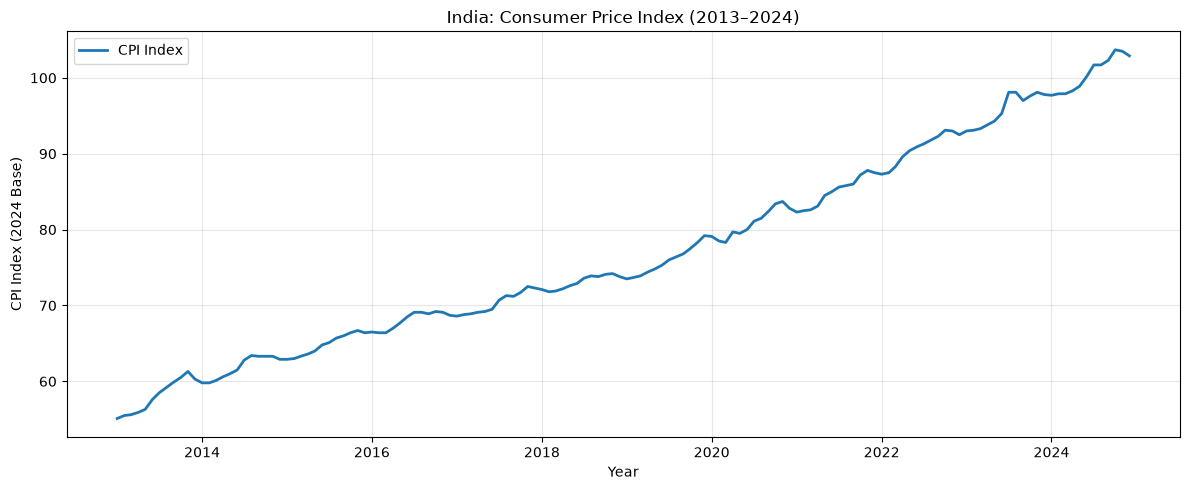

In [56]:
plt.figure(figsize=(12, 5))

plt.plot(
    cpi.index,
    cpi["index"],
    linewidth=2,
    label="CPI Index"
)

plt.title("India: Consumer Price Index (2013–2024)")
plt.xlabel("Year")
plt.ylabel("CPI Index (2024 Base)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "figure_01_cpi_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

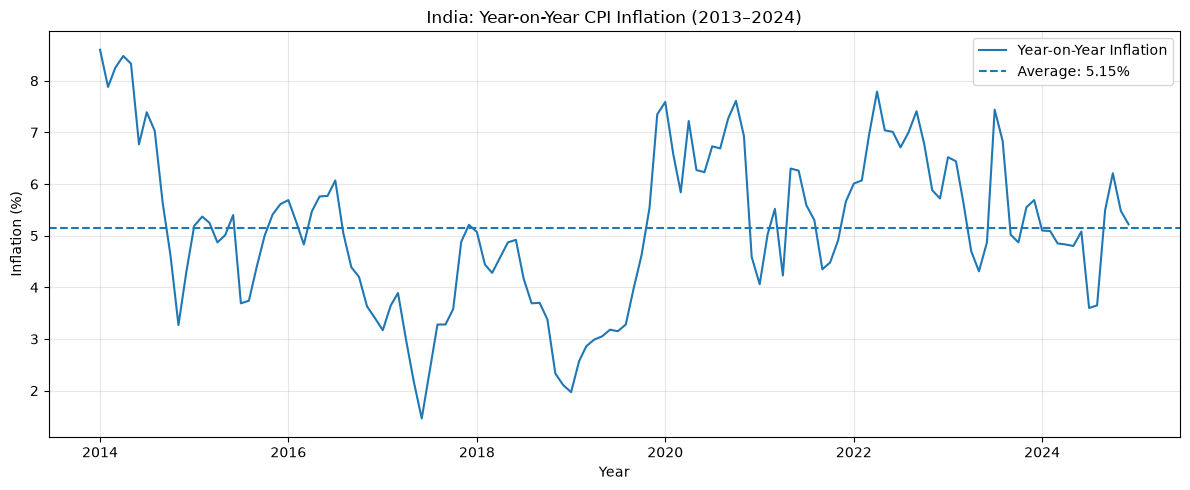

In [57]:
plt.figure(figsize=(12, 5))

plt.plot(
    cpi.index,
    cpi["inflation"],
    linewidth=1.5,
    label="Year-on-Year Inflation"
)

plt.axhline(
    cpi["inflation"].mean(),
    linestyle="--",
    linewidth=1.5,
    label=f"Average: {cpi['inflation'].mean():.2f}%"
)

plt.title("India: Year-on-Year CPI Inflation (2013–2024)")
plt.xlabel("Year")
plt.ylabel("Inflation (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "figure_02_inflation_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

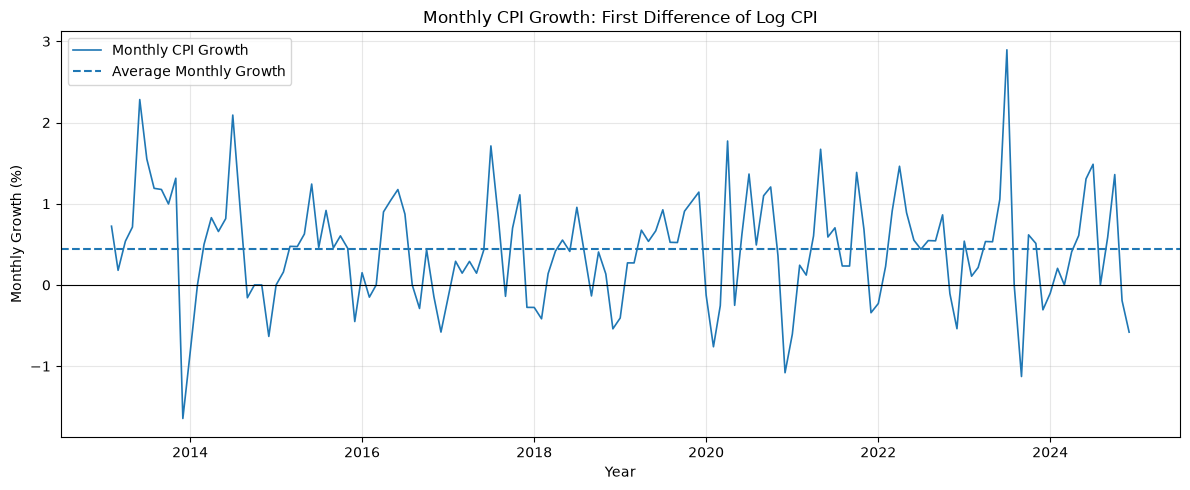

In [58]:
plt.figure(figsize=(12, 5))

plt.plot(
    growth_data.index,
    growth_data["d_log_cpi"] * 100,
    linewidth=1.2,
    label="Monthly CPI Growth"
)

plt.axhline(
    0,
    color="black",
    linewidth=0.8
)

plt.axhline(
    growth_data["d_log_cpi"].mean() * 100,
    linestyle="--",
    label="Average Monthly Growth"
)

plt.title("Monthly CPI Growth: First Difference of Log CPI")
plt.xlabel("Year")
plt.ylabel("Monthly Growth (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "figure_03_monthly_growth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

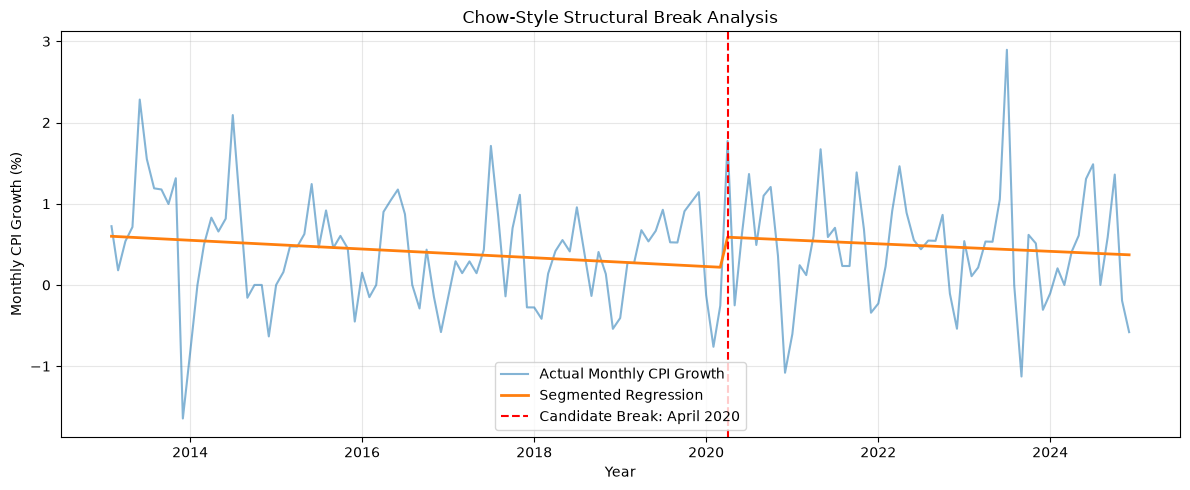

In [59]:
plt.figure(figsize=(12, 5))

plt.plot(
    growth_data.index,
    growth_data["d_log_cpi"] * 100,
    alpha=0.55,
    label="Actual Monthly CPI Growth"
)

plt.plot(
    growth_data.index,
    break_model.fittedvalues * 100,
    linewidth=2,
    label="Segmented Regression"
)

plt.axvline(
    break_date,
    color="red",
    linestyle="--",
    label="Candidate Break: April 2020"
)

plt.title("Chow-Style Structural Break Analysis")
plt.xlabel("Year")
plt.ylabel("Monthly CPI Growth (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "figure_04_chow_candidate_break.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

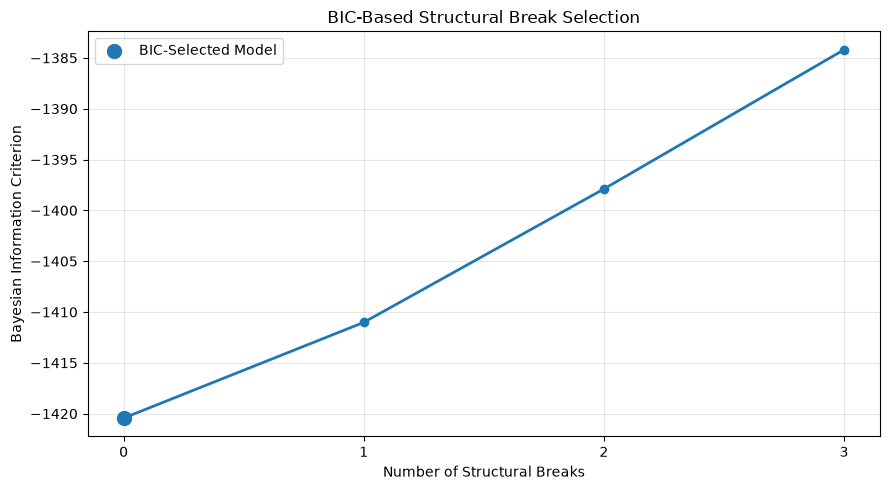

In [60]:
plt.figure(figsize=(9, 5))

plt.plot(
    dp_results["breaks"],
    dp_results["BIC"],
    marker="o",
    linewidth=2
)

plt.scatter(
    best_model["breaks"],
    best_model["BIC"],
    s=100,
    label="BIC-Selected Model",
    zorder=3
)

plt.xlabel("Number of Structural Breaks")
plt.ylabel("Bayesian Information Criterion")
plt.title("BIC-Based Structural Break Selection")
plt.xticks(dp_results["breaks"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "figure_05_bic_selection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [61]:
print("Generated figures:")

for file in sorted(FIGURE_DIR.glob("*.png")):
    print(file.name)

Generated figures:
S1_no_break.png
S2_intercept_break.png
S3_slope_break.png
S4_multiple_breaks.png
S5_variance_break.png
bai_perron_S1_no_break.png
bai_perron_S2_intercept_break.png
bai_perron_S3_slope_break.png
bai_perron_S4_multiple_breaks.png
bai_perron_S5_variance_break.png
cusum_S1_no_break.png
cusum_S2_intercept_break.png
cusum_S3_slope_break.png
cusum_S4_multiple_breaks.png
cusum_S5_variance_break.png
figure_01_cpi_trend.png
figure_02_inflation_trend.png
figure_03_monthly_growth.png
figure_04_chow_candidate_break.png
figure_05_bic_selection.png
pelt_S1_no_break.png
pelt_S2_intercept_break.png
pelt_S3_slope_break.png
pelt_S4_multiple_breaks.png
pelt_S5_variance_break.png
quandt_andrews_S1_no_break.png
quandt_andrews_S2_intercept_break.png
quandt_andrews_S3_slope_break.png
quandt_andrews_S4_multiple_breaks.png
simulated_multiple_breaks.png


In [62]:
# Create organized figure directories
SIMULATION_FIGURE_DIR = FIGURE_DIR / "simulation"
REAL_WORLD_FIGURE_DIR = FIGURE_DIR / "real_world"

SIMULATION_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
REAL_WORLD_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Move the five real-world figures
real_world_figures = [
    "figure_01_cpi_trend.png",
    "figure_02_inflation_trend.png",
    "figure_03_monthly_growth.png",
    "figure_04_chow_candidate_break.png",
    "figure_05_bic_selection.png"
]

for filename in real_world_figures:
    source = FIGURE_DIR / filename
    destination = REAL_WORLD_FIGURE_DIR / filename

    if source.exists():
        source.replace(destination)
        print("Moved:", filename)
    else:
        print("Not found:", filename)

print("\nFigure organization completed.")

Moved: figure_01_cpi_trend.png
Moved: figure_02_inflation_trend.png
Moved: figure_03_monthly_growth.png
Moved: figure_04_chow_candidate_break.png
Moved: figure_05_bic_selection.png

Figure organization completed.


In [63]:
# Move all remaining root-level PNG files into simulation/
for source in FIGURE_DIR.glob("*.png"):
    destination = SIMULATION_FIGURE_DIR / source.name

    if not destination.exists():
        source.replace(destination)
        print("Moved:", source.name)
    else:
        print("Already exists, skipped:", source.name)

print("\nOrganization completed.")

Moved: bai_perron_S5_variance_break.png
Moved: pelt_S3_slope_break.png
Moved: bai_perron_S1_no_break.png
Moved: S5_variance_break.png
Moved: pelt_S5_variance_break.png
Moved: quandt_andrews_S2_intercept_break.png
Moved: S3_slope_break.png
Moved: S2_intercept_break.png
Moved: pelt_S4_multiple_breaks.png
Moved: simulated_multiple_breaks.png
Moved: quandt_andrews_S1_no_break.png
Moved: cusum_S3_slope_break.png
Moved: cusum_S1_no_break.png
Moved: cusum_S4_multiple_breaks.png
Moved: S1_no_break.png
Moved: bai_perron_S2_intercept_break.png
Moved: cusum_S2_intercept_break.png
Moved: quandt_andrews_S3_slope_break.png
Moved: bai_perron_S4_multiple_breaks.png
Moved: cusum_S5_variance_break.png
Moved: pelt_S1_no_break.png
Moved: bai_perron_S3_slope_break.png
Moved: S4_multiple_breaks.png
Moved: quandt_andrews_S4_multiple_breaks.png
Moved: pelt_S2_intercept_break.png

Organization completed.


In [64]:
print("REAL-WORLD FIGURES:")
for file in sorted(REAL_WORLD_FIGURE_DIR.glob("*.png")):
    print(" -", file.name)

print("\nSIMULATION FIGURES:")
for file in sorted(SIMULATION_FIGURE_DIR.glob("*.png")):
    print(" -", file.name)

print("\nRemaining files in main figures directory:")
print([f.name for f in FIGURE_DIR.glob("*.png")])

REAL-WORLD FIGURES:
 - figure_01_cpi_trend.png
 - figure_02_inflation_trend.png
 - figure_03_monthly_growth.png
 - figure_04_chow_candidate_break.png
 - figure_05_bic_selection.png

SIMULATION FIGURES:
 - S1_no_break.png
 - S2_intercept_break.png
 - S3_slope_break.png
 - S4_multiple_breaks.png
 - S5_variance_break.png
 - bai_perron_S1_no_break.png
 - bai_perron_S2_intercept_break.png
 - bai_perron_S3_slope_break.png
 - bai_perron_S4_multiple_breaks.png
 - bai_perron_S5_variance_break.png
 - cusum_S1_no_break.png
 - cusum_S2_intercept_break.png
 - cusum_S3_slope_break.png
 - cusum_S4_multiple_breaks.png
 - cusum_S5_variance_break.png
 - pelt_S1_no_break.png
 - pelt_S2_intercept_break.png
 - pelt_S3_slope_break.png
 - pelt_S4_multiple_breaks.png
 - pelt_S5_variance_break.png
 - quandt_andrews_S1_no_break.png
 - quandt_andrews_S2_intercept_break.png
 - quandt_andrews_S3_slope_break.png
 - quandt_andrews_S4_multiple_breaks.png
 - simulated_multiple_breaks.png

Remaining files in main figur